# Quantitativee Easing  - VAR / VECM Analysis

*Data*: U.S quarterly, 2007 Q2 - 2021 Q4 (59 obs), Fed balance sheet, 10-year UST yield, S&P 500 P/E

## 0. Setup

In [9]:
import warnings, itertools
from pathlib import Path

import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import stats

import statsmodels
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_arch
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import VECM, coint_johansen

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)

plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,})

# ----- configuration ---------------------
SEED      = 2024      # bootstrap reproducibility
N_BOOT    = 1000      # bootstrap replications
H         = 20        # IRF horizon (quarters)
H_FEVD    = 8         # headline FEVD horizon (quarters)

Path("images").mkdir(exist_ok=True)  

# Approximate QE purchase windows (for shading only)
QE_PERIODS = [("2008-11", "2010-03"), ("2010-11", "2011-06"),
              ("2012-09", "2014-10"), ("2020-03", "2021-12")]


print(f"statsmodels {statsmodels.__version__} | pandas {pd.__version__} | numpy {np.__version__}")

statsmodels 0.15.0 | pandas 3.0.6 | numpy 2.5.4


## 1. Load and validate the data

In [10]:
CANDIDATES = Path("Data/US Fed New 1.2.csv")

DATA_PATH = CANDIDATES if CANDIDATES.exists() else None
if DATA_PATH is None:
    raise FileNotFoundError("Place US Fed New 1.2.csv next to this notebook or in ./Data/")

raw = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH} -> {raw.shape[0]} rows x {raw.shape[1]} columns")
display(raw.head(10))

Loaded Data\US Fed New 1.2.csv -> 60 rows x 10 columns


,Unnamed: 0,Date,Balance sheet,Date.1,Interest rate,SP PE,Balance sheet PC,UST 10,Unnamed: 8,Unnamed: 9
0,NaN,29/6/2007,8.659e+05,29/6/2007,5.25,15.982,0.000e+00,4.85,#NAME?,NaN
1,NaN,28/9/2007,8.907e+05,28/9/2007,4.75,16.635,2.855e-02,4.74,NaN,NaN
2,58.0,31/12/2007,8.912e+05,31/12/2007,4.25,16.525,5.468e-04,4.27,NaN,#REF!
3,NaN,31/3/2008,8.944e+05,31/3/2008,2.25,15.993,3.679e-03,3.67,NaN,-3.1%
4,NaN,30/6/2008,8.932e+05,30/6/2008,2.00,15.230,-1.387e-03,3.88,NaN,-26.5%
5,NaN,30/9/2008,1.212e+06,30/9/2008,2.00,15.429,3.573e-01,3.86,NaN,-60.2%
6,NaN,31/12/2008,2.240e+06,31/12/2008,0.25,15.143,8.476e-01,3.23,NaN,-56.8%
7,NaN,31/3/2009,2.072e+06,31/3/2009,0.25,11.639,-7.501e-02,2.74,NaN,-55.9%
8,NaN,30/6/2009,2.026e+06,30/6/2009,0.25,11.735,-2.221e-02,3.32,NaN,-43.4%
9,NaN,30/9/2009,2.141e+06,30/9/2009,0.25,14.343,5.700e-02,3.52,NaN,0.2%


In [11]:
df = raw[["Date", "Balance sheet", "UST 10", "SP PE"]].copy()
df.columns = ["date", "balance_sheet", "ust10", "pe"]
df["date"] = pd.to_datetime(df["date"], dayfirst=True)      # file uses DD/MM/YYYY
df = df.dropna().sort_values("date").reset_index(drop=True)

# Balance sheet is in $ millions. Convert to $ trillions, then take the log:
# changes in a log series are growth rates, and the series grows roughly exponentially.
df["log_bs"] = np.log(df["balance_sheet"] / 1e6)                 

quarters = pd.PeriodIndex(df["date"], freq="Q")          # label each row with its quarter, e.g. 2008Q4
df.head()

,date,balance_sheet,ust10,pe,log_bs
0,2007-06-29,865949.0,4.85,15.982,-0.144
1,2007-09-28,890671.0,4.74,16.635,-0.116
2,2007-12-31,891158.0,4.27,16.525,-0.115
3,2008-03-31,894437.0,3.67,15.993,-0.112
4,2008-06-30,893196.0,3.88,15.230,-0.113


In [12]:
# Basic consistency checks
pe_by_q = df.set_index(quarters)["pe"]
pe_2018q4 = 100 * (pe_by_q["2018Q4"] / pe_by_q["2018Q3"] - 1)
pe_2019q1 = 100 * (pe_by_q["2019Q1"] / pe_by_q["2018Q4"] - 1)
pct_change_ok = np.allclose(raw["Balance sheet PC"].iloc[:1], raw["Balance sheet"].pct_change().iloc[:1], atol=1e-6)

checks = pd.DataFrame([
    ("Number of observations",            len(df),                                   "PASS", "Small for a 3-variable VECM, so expect wide uncertainty"),
    ("One row per quarter, none skipped", bool((pd.Series(quarters.asi8).diff().dropna() == 1).all()), "PASS", ""),
    ("Missing values",                    int(df[["balance_sheet", "ust10", "pe"]].isna().sum().sum()), "PASS", ""),
    ("Date columns identical",            bool(raw["Date"].equals(raw["Date.1"])),   "PASS", ""),
    ("Pre-computed % change matches",     bool(pct_change_ok),                       "PASS", "Cross-checks the balance-sheet column"),
    ("All values positive",               bool((df[["balance_sheet", "ust10", "pe"]] > 0).all().all()), "PASS", ""),
    ("P/E direction vs known S&P moves",  f"P/E {pe_2018q4:+.1f}% in 2018Q4, {pe_2019q1:+.1f}% in 2019Q1",
                                          "REVIEW", "S&P fell 13.97% then rose 13.07%: possible one-quarter dating issue"),
], columns=["check", "result", "status", "note"]).set_index("check")
display(checks)

print("P/E and yield around the anomaly:")
display(df.set_index(quarters).loc["2018Q2":"2019Q3", ["pe", "ust10"]])

,result,status,note
check,,,
Number of observations,59,PASS,"Small for a 3-variable VECM, so expect wide un..."
"One row per quarter, none skipped",True,PASS,
Missing values,0,PASS,
Date columns identical,True,PASS,
Pre-computed % change matches,False,PASS,Cross-checks the balance-sheet column
All values positive,True,PASS,
P/E direction vs known S&P moves,"P/E +2.2% in 2018Q4, -19.3% in 2019Q1",REVIEW,S&P fell 13.97% then rose 13.07%: possible one...


P/E and yield around the anomaly:


,pe,ust10
date,,
2018Q2,21.184,2.92
2018Q3,20.323,2.92
2018Q4,20.765,3.04
2019Q1,16.756,2.65
2019Q2,18.417,2.34
2019Q3,19.117,1.80


In [13]:
changes_to_check = {"Δ log(BS)": df["log_bs"].diff(), "Δ UST10": df["ust10"].diff(), "Δ P/E": df["pe"].diff()}

flagged = []
for name, s in changes_to_check.items():
    z = (s - s.median()) / (1.4826 * (s - s.median()).abs().median())   # robust z-score 
    for i in z.index[z.abs() > 3.5]:
        flagged.append({"series": name, "quarter": str(quarters[i]), "change": s[i], "robust z": z[i]})
pd.DataFrame(flagged)

,series,quarter,change,robust z
0,Δ log(BS),2008Q3,0.305,7.637
1,Δ log(BS),2008Q4,0.614,15.504
2,Δ log(BS),2020Q1,0.232,5.768
3,Δ log(BS),2020Q2,0.299,7.461
4,Δ P/E,2019Q1,-4.008,-3.858
5,Δ P/E,2020Q2,-4.562,-4.370
6,Δ P/E,2020Q3,4.611,4.107
7,Δ P/E,2020Q4,3.972,3.516
8,Δ P/E,2021Q4,-4.271,-4.101


## Explore the data

Analyse the three series: log balance sheet, 10-year yield, P/E

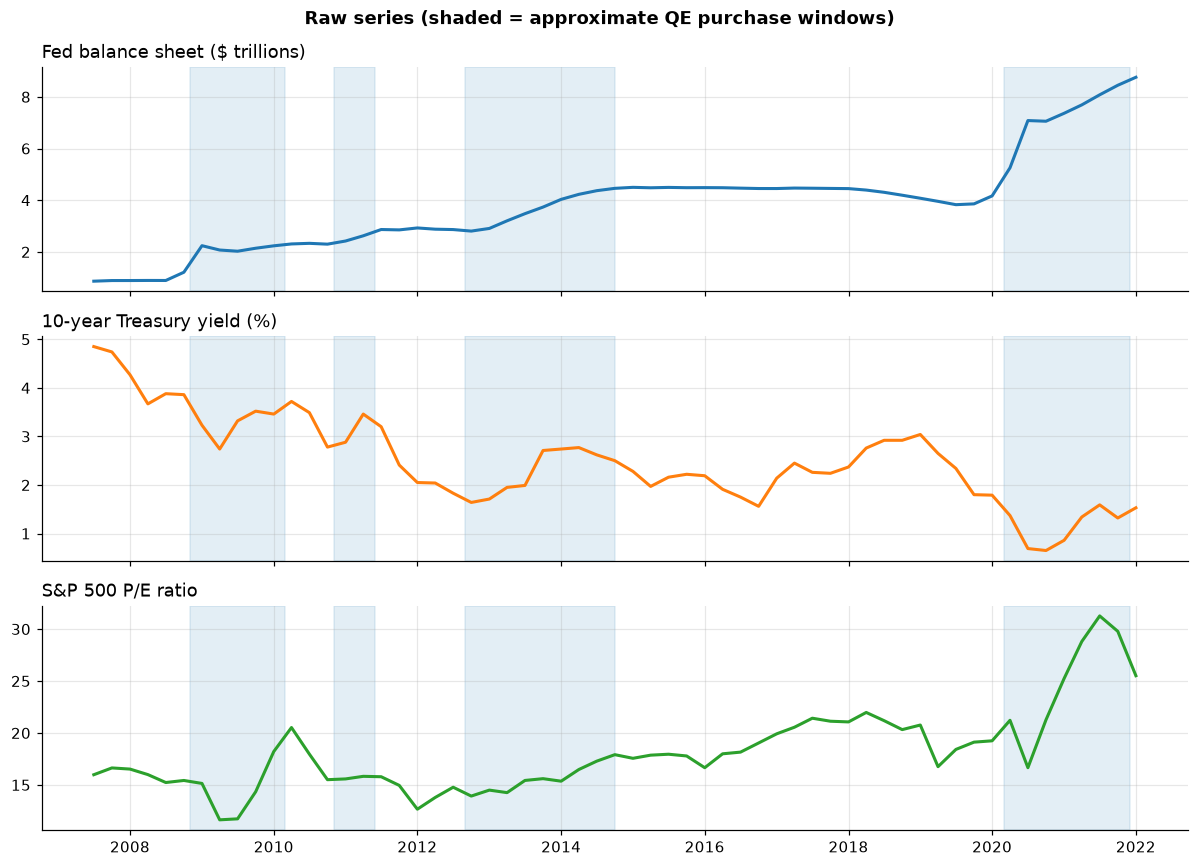

Correlations in levels (don't trust these: trending series correlate spuriously):


,log_bs,ust10,pe
log_bs,1.000,-0.842,0.628
ust10,-0.842,1.000,-0.398
pe,0.628,-0.398,1.000


In [14]:
levels = df.set_index(quarters)[["log_bs", "ust10", "pe"]]   # the three series, in levels
names  =list(levels.columns)
dates = levels.index.to_timestamp(how="end")     # real dates, for plotting only

def shade_qe(ax):
    for start, end in QE_PERIODS:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="tab:blue", alpha=0.12)

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].plot(dates, df["balance_sheet"].values / 1e6, color="tab:blue", lw=2)
axes[0].set_title("Fed balance sheet ($ trillions)", loc="left")
axes[1].plot(dates, levels["ust10"], color="tab:orange", lw=2)
axes[1].set_title("10-year Treasury yield (%)", loc="left")
axes[2].plot(dates, levels["pe"], color="tab:green", lw=2)
axes[2].set_title("S&P 500 P/E ratio", loc="left")
for ax in axes:
    shade_qe(ax)
fig.suptitle("Raw series (shaded = approximate QE purchase windows)", fontweight="bold")
fig.tight_layout()
fig.savefig("images/01_series.png", dpi=150, bbox_inches="tight")
plt.show()

print("Correlations in levels (don't trust these: trending series correlate spuriously):")
levels.corr()


## 2. Unit-Roots Tests

**Why it matters:** regressing one wandering (non-stationary) series on another can produce "significant" results that are meaningless. Before modelling, we test each series with two tests that have *opposite* null hypotheses, so they cross-check each other:

| Test | Null hypothesis | "Stationary" looks like |
|---|---|---|
| ADF | has a unit root (non-stationary) | small p-value |
| KPSS | is stationary | large p-value |

(`statsmodels` limits KPSS p-values to the range 0.01–0.10.) We also run both with a trend term as a check.

In [15]:
def unit_root_table(frame):
    rows = []
    for col in frame.columns:
        s = frame[col]
        adf_p = adfuller(s, regression="c", autolag="AIC")[1]
        adf_trend = adfuller(s, regression="ct", autolag="AIC")[1]
        kpss_p     = kpss(s, regression="c",  nlags="auto")[1]
        kpss_trend = kpss(s, regression="ct", nlags="auto")[1]

        if adf_p < 0.05 and kpss_p > 0.05:
            verdict = "stationary"
        elif adf_p >= 0.05 and kpss_p <= 0.05:
            verdict = "unit root"
        else:
            verdict = "ambiguous"
        rows.append({"series": col, "ADF p": adf_p, "ADF p (trend)": adf_trend,
                     "KPSS p": kpss_p, "KPSS p (trend)": kpss_trend, "verdict": verdict})
    return pd.DataFrame(rows).set_index("series")

changes = levels.diff().dropna()     # first differences: this quarter minus last quarter

print("LEVELS"); display(unit_root_table(levels))
print("FIRST DIFFERENCES"); display(unit_root_table(changes))

LEVELS


,ADF p,ADF p (trend),KPSS p,KPSS p (trend),verdict
series,,,,,
log_bs,0.330,0.160,0.01,0.020,unit root
ust10,0.257,0.374,0.01,0.083,unit root
pe,0.994,0.663,0.01,0.049,unit root


FIRST DIFFERENCES


,ADF p,ADF p (trend),KPSS p,KPSS p (trend),verdict
series,,,,,
log_bs,3.686e-06,3.633e-05,0.1,0.079,stationary
ust10,7.996e-04,5.034e-03,0.1,0.100,stationary
pe,2.786e-02,2.230e-02,0.1,0.100,stationary


## 3. VAR on the changes

Variables: Δlog(balance sheet) (the quarterly growth rate), ΔUST10, ΔP/E.

**3a. How many lags?** Information criteria (lower is better) are checked from lag 0, so "no dynamics" is a possible answer.

In [17]:
lag_choice = VAR(changes).select_order(maxlags=4)
display(pd.DataFrame(lag_choice.ics, index=range(5)).rename_axis("lags"))
print("Best lag by each criterion:", {k: int(v) for k, v in lag_choice.selected_orders.items()})

,aic,bic,hqic,fpe
lags,,,,
0,-5.510,-5.400,-5.468,0.004
1,-5.456,-5.014,-5.286,0.004
2,-5.405,-4.631,-5.107,0.005
3,-5.315,-4.210,-4.889,0.005
4,-5.373,-3.937,-4.819,0.005


Best lag by each criterion: {'aic': 0, 'bic': 0, 'hqic': 0, 'fpe': 0}


**Every criterion picks lag 0:** once you take changes, there is almost no predictable short-run pattern left. A VAR(0) can't show dynamics, so we fit **VAR(1)**, the smallest model that can, and see what it finds.

In [18]:
var1 = VAR(changes).fit(1)

print("Coefficients (each column is one equation):")
display(var1.params)
print("p-values:")
display(var1.pvalues)

# R-squared: how much of each variable's variation the model explains
r_squared = {col: round(1 - var1.resid[col].var() / changes[col].iloc[1:].var(), 3) for col in changes}
print("R-squared:", r_squared)

Coefficients (each column is one equation):


,log_bs,ust10,pe
const,0.029,-0.011,0.280
L1.log_bs,0.342,-0.841,-2.416
L1.ust10,0.050,0.192,0.757
L1.pe,0.004,0.002,0.078


p-values:


,log_bs,ust10,pe
const,0.048,0.815,0.300
L1.log_bs,0.009,0.052,0.320
L1.ust10,0.257,0.188,0.354
L1.pe,0.670,0.941,0.618


R-squared: {'log_bs': np.float64(0.134), 'ust10': np.float64(0.121), 'pe': np.float64(0.059)}
